# 1. Introduction

The **image deblurring** problem consists of recovering the original image from a blurred, noise-contaminated observation, such as an image acquired by a camera or telescope. This is a classical inverse problem in which the mechanism responsible for the blurring is assumed known, and the goal is to estimate the image that produced the observation.

Examples of physical mechanisms that cause image blurring include:

- Imperfections in optical components, such as lenses or mirrors.
- Atmospheric refraction and turbulence.

# 2. Basic theory

Consider a grayscale image represented by a matrix:

\begin{equation}
\mathbf{X}_{\mathrm{true}} \in \mathbb{R}^{M\times L},
\tag{1}
\end{equation}

with $M$ rows and $L$ columns. The image blurring process can be modeled as a two-dimensional convolution,

\begin{equation}
\mathbf{B} = \mathbf{H} * \mathbf{X}_{\mathrm{true}},
\tag{2}
\end{equation}

where $\mathbf{H}$ represents the *point spread function* (PSF).

The PSF describes how the imaging system spreads an ideal point in the original image. For example, when the PSF is Gaussian, each pixel in the original image contributes to a small surrounding region, producing a blurring effect. The wider the PSF, the stronger the blur.

In the `ImageDeblur` toy problem, we use a normalized Gaussian PSF, such that:

\begin{equation}
\sum_{i,j} H_{ij}=1.
\end{equation}

This normalization ensures that the blurring process redistributes pixel intensities spatially without ideally changing the total image intensity.

To express the problem in the standard form of a linear system, we can reshape the image into a vector. Let

\begin{equation}
\mathbf{x}_{\mathrm{true}}
=
\operatorname{vec}(\mathbf{X}_{\mathrm{true}})
\in \mathbb{R}^{ML}.
\end{equation}

The convolution can then be represented as

\begin{equation}
\mathbf{b}
=
\mathbf{A}\mathbf{x}_{\mathrm{true}},
\tag{3}
\end{equation}

where

\begin{equation}
\mathbf{A}\in\mathbb{R}^{ML\times ML}
\end{equation}

is the matrix representing the blurring operation. In the presence of measurement noise, the observation model becomes

\begin{equation}
\mathbf{b}
=
\mathbf{A}\mathbf{x}_{\mathrm{true}}+\mathbf{n},
\tag{4}
\end{equation}

where $\mathbf{n}$ represents the noise affecting the observed image.

Let us now set up the problem using `PyRegTools`, initially working with a moderately sized problem and an explicitly constructed matrix. We will examine the blurring process and investigate how the dimensions of $\mathbf{A}$ grow with image size. For moderately sized problems, we can still attempt to solve the inverse problem using conventional matrix-based methods.

In [1]:
import numpy as np
import scipy
import matplotlib.pyplot as plt
from pyregtools.toyproblems import ImageDeblur
from pyregtools.regsolvers import csvd, tikhonov
from pyregtools.iterativesolvers import landweber, cgls
from pyregtools.regchoice import gcv_lambda, lcurve_discrete
from pyregtools.utils import nmse_fun

In [2]:
size = 64 # Don't force the friendship here. Be warned.
problem = ImageDeblur(image_name="photo0.png", shape=(size, size))
problem.gaussian_psf(sigma=1.5)
problem.blur_kron()
problem.add_noise(snr=45, seed=42)
b_blur_mtx = np.copy(problem.b_blur)
nmse_b = nmse_fun(x_meas = problem.b_noisy, x_ref = problem.b_true)
# Estimate the memory usage of this image
memo = len(problem.A.ravel())*8/((1024**3))
print("Matrix shape is {} ({} GB)".format(problem.A.shape, memo))

Matrix shape is (4096, 4096) (0.125 GB)


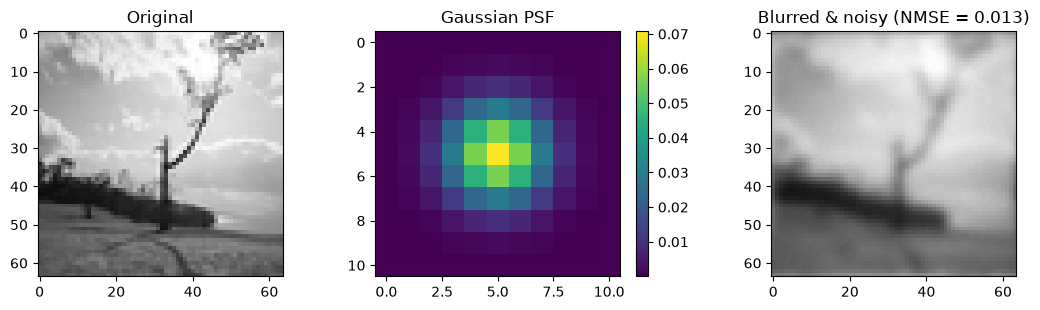

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
ax[0].imshow(problem.b_true, cmap="gray", vmin=0, vmax=1)
ax[0].set_title("Original")
im = ax[1].imshow(problem.psf, cmap="viridis")
ax[1].set_title("Gaussian PSF")
ax[2].imshow(problem.b_noisy, cmap="gray", vmin=0, vmax=1)
ax[2].set_title("Blurred & noisy (NMSE = {:.3f})".format(nmse_b))
fig.colorbar(im, ax=ax[1])
plt.tight_layout()

## 2.1. Problem Size

An important computational challenge quickly becomes apparent. An image with only $64\times64$ pixels contains $64^2=4096$ pixels (or unknowns, from the perspective of the inverse problem). If we explicitly represent the convolution operator as a dense matrix, we obtain

\begin{equation}
\mathbf{A}\in
\mathbb{R}^{4096\times4096},
\end{equation}

containing approximately $16.8\times10^6$ elements. Storing each element as a `float64` (64 bits or 8 bytes) requires approximately 0.125 GiB of memory.

For a $256\times256$ image, we would have 65,536 pixels (unknowns), resulting in a matrix:

\begin{equation}
\mathbf{A}\in
\mathbb{R}^{65536\times65536},
\end{equation}

with more than $4.29\times10^9$ elements, requiring approximately 32 GiB of memory to store $\mathbf{A}$.

This rapid growth illustrates an important computational limitation: although the inverse problem can formally be written as $\mathbf{A}\mathbf{x}=\mathbf{b}$, explicitly constructing and factorizing $\mathbf{A}$ quickly becomes impractical.

Nevertheless, conventional matrix-based regularization methods remain useful for smaller problems, where the computational and memory requirements are manageable.

## 2.2. Tikhonov Deblurring

Let us first attempt to recover the original image using **Tikhonov regularization**, with automatic selection of the regularization parameter through **Generalized Cross-Validation (GCV)**.

We will follow these steps:

1. Compute the singular value decomposition (SVD) of $\mathbf{A}$.
2. Estimate the regularization parameter using GCV.
3. Solve the inverse problem using the `tikhonov` solver.
4. Visualize and analyze the reconstructed image. 

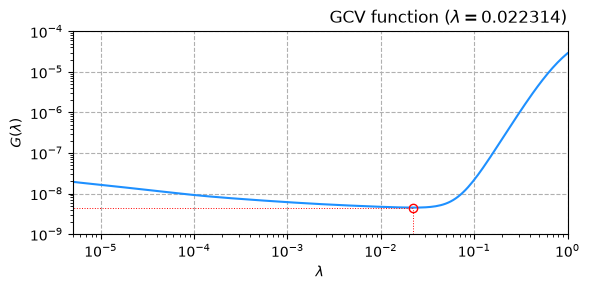

In [5]:
u, s, v = csvd(problem.A)
lam_opt = gcv_lambda(u, s, problem.b_noisy.ravel(order="C"), plotit = True, r_min=0.000005)
x_est = tikhonov(u, s, v, problem.b_noisy.ravel(order="C"), lam_opt)
x_est = np.reshape(x_est, problem.shape, order="C")
nmse = nmse_fun(x_meas = x_est, x_ref = problem.b_true)

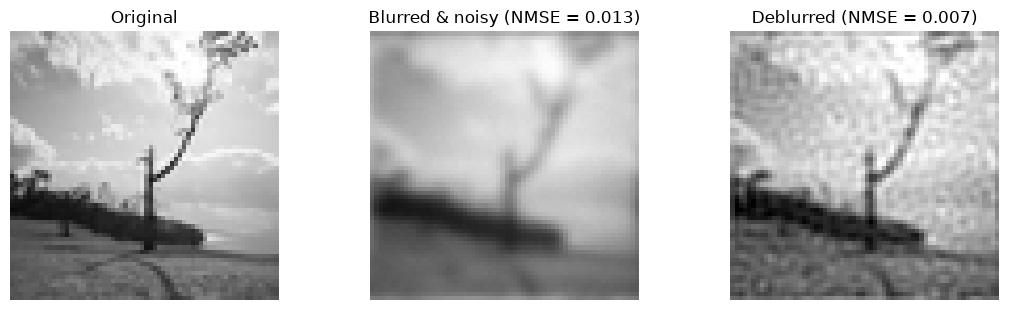

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
ax[0].imshow(problem.b_true, cmap="gray", vmin=0, vmax=1)
ax[0].set_title("Original")
ax[1].imshow(problem.b_noisy, cmap="gray", vmin=0, vmax=1)
ax[1].set_title("Blurred & noisy (NMSE = {:.3f})".format(nmse_b))
ax[2].imshow(x_est, cmap="gray", vmin=0, vmax=1)
ax[2].set_title("Deblurred (NMSE = {:.3f})".format(nmse))
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

### Question: What did you notice?

<details>
  <summary><b>▶ Click here to reveal the answer</b></summary>

  ### Answer

- The computations took a considerable amount of time.
- The NMSE of the reconstructed solution is significantly lower.
- However, the reconstruction is not perfect and still exhibits some noise-related artifacts.

</details>

## 2.3. Computing the Forward Problem Without Constructing the Matrix

Although the forward problem can be expressed as $\mathbf{b}=\mathbf{A}\mathbf{x}$, explicitly constructing the matrix $\mathbf{A}$ is not necessary to compute the blurred image. Instead, we can exploit properties of the convolution operation to perform this calculation much more efficiently.

### 2.3.1. Separable Convolution

In the problem considered here, the Gaussian PSF is **separable**, meaning that $A(x,y)=A_x(x)A_y(y)$. This implies that the two-dimensional convolution can be decomposed into two one-dimensional convolutions: one along the rows and another along the columns.

Consequently, the two-dimensional convolution can be expressed as

\begin{equation}
\mathbf{B}
=
\mathbf{A}_y
\mathbf{X}_{\mathrm{true}}
\mathbf{A}_x^T,
\tag{5}
\end{equation}

where $\mathbf{A}_y\in\mathbb{R}^{M\times M}$ and $\mathbf{A}_x\in\mathbb{R}^{L\times L}$ represent the one-dimensional convolution operators along the vertical and horizontal directions, respectively.

This approach is implemented in the `blur_separable` method of the `ImageDeblur` class and significantly reduces both the computational cost and memory requirements of evaluating the forward problem.

In [7]:
problem.blur_separable()
b_blur_sep = np.copy(problem.b_blur)
err_norm_sep = np.linalg.norm(b_blur_sep-b_blur_mtx)

print("Full Matrix shape is {} ({} GB)".format(problem.A.shape, memo))
print(r"Matrix A_y shape is {}".format(problem.A_y.shape))
print(r"Matrix A_x shape is {}".format(problem.A_x.shape))

Full Matrix shape is (4096, 4096) (0.125 GB)
Matrix A_y shape is (64, 64)
Matrix A_x shape is (64, 64)


### 2.3.2. Convolution Using the FFT (Fast Fourier Transform)

Another approach is to compute the convolution in the frequency domain. According to the **convolution theorem**, the convolution in the spatial domain corresponds to multiplication in the frequency domain:

\begin{equation}
\mathcal{F}\mathcal{F}\{\mathbf{H} * \mathbf{X}\}
=
\mathcal{F}\mathcal{F}\{\mathbf{H}\}
\odot
\mathcal{F}\mathcal{F}\{\mathbf{X}\},
\tag{6}
\end{equation}

where $\mathcal{F}\mathcal{F}\{\cdot\}$ denotes the two-dimensional Fourier transform and $\odot$ represents element-wise multiplication.

Thus, the blurred image can be computed as

\begin{equation}
\mathbf{B}
=
\mathcal{F}^{-1}\mathcal{F}^{-1}
\left\{
\mathcal{F}\mathcal{F}\{\mathbf{H}\}
\odot
\mathcal{F}\mathcal{F}\{\mathbf{X}_{\mathrm{true}}\}
\right\},
\tag{7}
\end{equation}

where $\mathcal{F}\mathcal{F}\{\mathbf{X}_{\mathrm{true}}\}\in\mathbb{C}^{M\times L}$ and $\mathcal{F}\mathcal{F}\{\mathbf{H}\}\in\mathbb{C}^{M\times L}$. Here, $\mathbf{H}$ denotes the PSF embedded in an array of the same dimensions as the image, with its center shifted to zero lag. The FFT implementation in the `ImageDeblur` class of `PyRegTools` assumes periodic boundary conditions, corresponding to circular convolution. Other boundary conditions require different implementations of the forward operator.

This approach is implemented in the `blur_fft` method. For larger images, the FFT provides a computationally efficient way to evaluate the convolution without explicitly constructing the matrix $\mathbf{A}$.

Both `blur_separable` and `blur_fft` therefore allow us to apply the forward operator directly to an image, avoiding the storage of the large matrix associated with the convolution.

In [8]:
problem.blur_fft()
b_blur_fft = np.copy(problem.b_blur)
err_norm_fft = np.linalg.norm(b_blur_fft-b_blur_mtx)
print("Full matrix shape is {} ({} GB)".format(problem.A.shape, memo))
print(r"Matrix H_fft shape is {}".format(problem.H_fft.shape))
print(r"Matrix X_true shape is {}".format(problem.b_true.shape))

Full matrix shape is (4096, 4096) (0.125 GB)
Matrix H_fft shape is (64, 64)
Matrix X_true shape is (64, 64)


### Comparing all the blurring methods in `ImageDeblur`

- Computing the forward problem using `blur_separable` or `blur_fft` is much more efficient and drastically reduces the computational and memory requirements.
- Can we also solve the inverse problem without explicitly constructing the matrix $\mathbf{A}$?
- The answer is **yes**. Although strategies such as Tikhonov regularization implemented in `PyRegTools` were not designed to operate directly on two-dimensional images
- However, the module `iterative_solvers` can exploit these efficient implementations of the forward operator to solve the inverse problem without constructing $\mathbf{A}$.

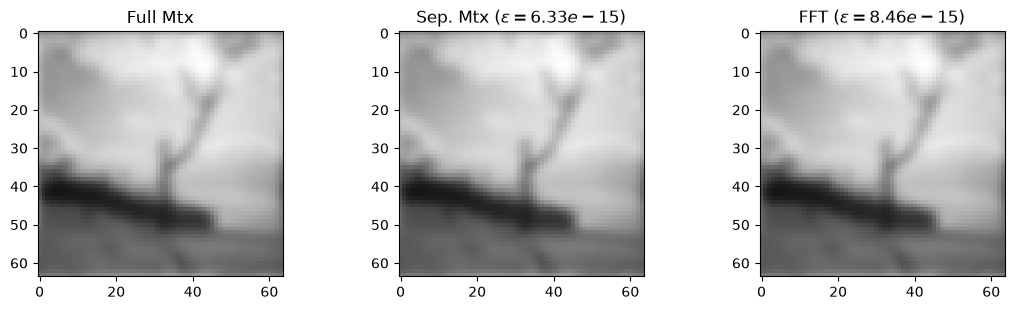

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
ax[0].imshow(b_blur_mtx, cmap="gray", vmin=0, vmax=1)
ax[0].set_title("Full Mtx")
ax[1].imshow(b_blur_sep, cmap="gray", vmin=0, vmax=1)
ax[1].set_title(r"Sep. Mtx ($\epsilon = {:.2e}$)".format(err_norm_sep))
ax[2].imshow(b_blur_fft, cmap="gray", vmin=0, vmax=1)
ax[2].set_title(r"FFT ($\epsilon = {:.2e}$)".format(err_norm_fft))
plt.tight_layout()

We have now implemented the same blurring process using three different approaches: an explicit matrix, separable convolution, and FFT-based convolution. The latter two approaches substantially reduce memory requirements and computational cost while producing equivalent results.

But can we also **solve the inverse problem without explicitly constructing** $\mathbf{A}$?

The answer is **yes**. Iterative methods such as Landweber and CGLS require only the forward operator and its adjoint. By implementing these operations efficiently using the FFT, we can solve much larger inverse problems without storing or factorizing the system matrix.

# 3. Some Stationary Iterative Methods

This notebook will introduce two **iterative regularization** methods with a brief discussion. Studying these methods provides insight into fundamental mechanisms of iterative regularization and helps establish connections to the regularization methods introduced earlier.

First, let's create an interestingly large image to work with.

In [10]:
size = 400
problem = ImageDeblur(image_name="moon.png", shape=(size, size))
problem.gaussian_psf(sigma=2.5)
problem.blur_fft()
problem.add_noise(snr=45, seed=42)
nmse_b = nmse_fun(x_meas = problem.b_noisy, x_ref = problem.b_true)
memo = ((size**2)**2)*8/((1024**3))
print("Matrix shape is {} x {} ({:.2f} GB)".format(size**2, size**2, memo))

Matrix shape is 160000 x 160000 (190.73 GB)


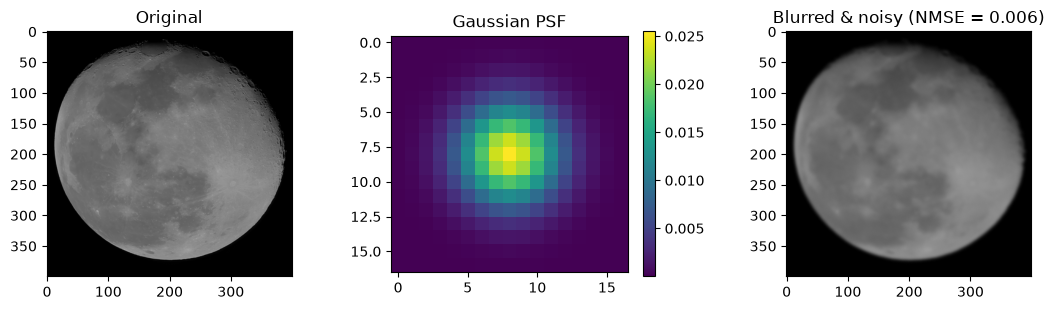

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
ax[0].imshow(problem.b_true, cmap="gray", vmin=0, vmax=1)
ax[0].set_title("Original")
im = ax[1].imshow(problem.psf, cmap="viridis")
ax[1].set_title("Gaussian PSF")
ax[2].imshow(problem.b_noisy, cmap="gray", vmin=0, vmax=1)
ax[2].set_title("Blurred & noisy (NMSE = {:.3f})".format(nmse_b))
fig.colorbar(im, ax=ax[1])
plt.tight_layout()

## 3.1. Landweber Method

One of the best-known iterative methods that exhibits **semiconvergence** is the Landweber method. It can be interpreted as **gradient descent** applied to the least-squares problem, given by

\begin{equation}
\min_{\mathbf{x}} J(\mathbf{x}),
\qquad
J(\mathbf{x}) = \frac{1}{2}\|\mathbf{A}\mathbf{x}-\mathbf{b}\|_2^2.
\tag{8}
\end{equation}

The gradient of the objective function is

\begin{equation}
\nabla J(\mathbf{x})
=
\mathbf{A}^H(\mathbf{A}\mathbf{x}-\mathbf{b})
=
-\mathbf{A}^H\mathbf{r}.
\tag{9}
\end{equation}

Therefore, the quantity $\mathbf{A}^H\mathbf{r}$ indicates a direction in which the current solution can be corrected to reduce the least-squares error. At each iteration, the method computes the discrepancy between the measured data and the data predicted by the model, $\mathbf{r}=\mathbf{b}-\mathbf{A}\mathbf{x}$, and propagates this information back to the solution space through $\mathbf{A}^H$ to update the solution.

A gradient descent iteration is given by

\begin{equation}
\mathbf{x}^{[k+1]}
=
\mathbf{x}^{[k]}
-
\omega\nabla J(\mathbf{x}^{[k]}).
\end{equation}

where the parameter $\omega$ controls the step size along this direction. Substituting the gradient, the solution update becomes

\begin{equation}
\mathbf{x}^{[k+1]}
=
\mathbf{x}^{[k]}
+
\omega
\overbrace{\mathbf{A}^{H}}^{\text{adjoint}}
\underbrace{\left(\mathbf{b}-\mathbf{A}\mathbf{x}^{[k]}\right)}_{\text{residual}}.
\tag{10}
\end{equation}

To ensure convergence, the relaxation parameter must satisfy:

\begin{equation}
0 < \omega <
\frac{2}{\|\mathbf{A}^{H}\mathbf{A}\|_2}
=
\frac{2}{\sigma_1^2},
\tag{11}
\end{equation}

where $\sigma_1$ is the largest singular value of $\mathbf{A}$. Thus, each iteration requires computing the residual, applying $\mathbf{A}^H $, and updating the solution. No matrix factorization is required.

## 3.2. The Adjoint Matrix vs. the Inverse Matrix

The operation $\mathbf{A}^{-1}\mathbf{b}=\mathbf{x}$, when the inverse exists, aims to undo the action of $\mathbf{A}\mathbf{x}=\mathbf{b}$. The matrix $\mathbf{A}^H$, on the other hand, is the **adjoint** of $\mathbf{A}$ and serves a different purpose: it relates variations in the solution space to quantities in the data space.

Consider a small perturbation $\delta\mathbf{x}$ in the solution. The corresponding perturbation in the data is $\mathbf{A}\delta\mathbf{x}$. To compare this perturbation with the residual $\mathbf{r}$, we compute the inner product:

\begin{equation}
\langle \mathbf{A}\delta\mathbf{x},\mathbf{r}\rangle.
\end{equation}

By the definition of the adjoint,

\begin{equation}
\langle \mathbf{A}\delta\mathbf{x},\mathbf{r}\rangle
=
\langle\delta\mathbf{x},\mathbf{A}^H\mathbf{r}\rangle.
\end{equation}

Thus, $\mathbf{A}^H\mathbf{r}$ expresses, in the solution space, the information contained in the residual that is relevant for **modifying** $\mathbf{x}$. It does not undo the forward problem; instead, it provides a **correction direction**.


### Applying $\mathbf{A}$ without constructing $\mathbf{A}$

The matrix formulation is very useful for understanding the problem,

\begin{equation}
\mathbf{b} = \mathbf{A}\mathbf{x},
\end{equation}

but this does not mean that we need to explicitly construct and store the matrix $\mathbf{A}$.

To apply some of the iterative methods in `PyRegTools`, we essentially need two operations:

\begin{equation}
\mathbf{x} \longmapsto \mathbf{A}\mathbf{x}
\end{equation}

and

\begin{equation}
\mathbf{y} \longmapsto \mathbf{A}^H\mathbf{y}.
\end{equation}

The first operation computes the data predicted by a given trial solution through the forward model. The second applies the adjoint operator, mapping a quantity from the data space back to the solution space.

Importantly, the second operation **does not solve the inverse problem**. It does not attempt to undo the effect of the forward operator. In the Landweber method, its role is to transform the residual computed in the data space into a correction direction in the solution space.

In the *image deblurring* problem, both operations can be evaluated directly using the FFT, without explicitly constructing the matrix $\mathbf{A}$.

### Forward and Adjoint Operators Using the FFT

If the blurring process is described by the convolution of an image with a PSF, the forward problem can be evaluated in the frequency domain as

\begin{equation}
\widehat{\mathbf{B}}
=
\mathcal{F}\mathcal{F}\{\mathbf{H}\}
\odot
\mathcal{F}\mathcal{F}\{\mathbf{X}_{\mathrm{true}}\}
=
\widehat{\mathbf{H}}\odot\widehat{\mathbf{X}}_{\mathrm{true}},
\end{equation}

where $\odot$ denotes element-wise multiplication.

We can also define the adjoint operation. Consider an image $\mathbf{Y}$ belonging to the data space. Applying the adjoint operator produces an image $\mathbf{Z}$ in the solution space:

\begin{equation}
\mathbf{Z}
=
\mathcal{F}^{-1}\mathcal{F}^{-1}
\left\{
\overline{\widehat{\mathbf{H}}}
\odot
\widehat{\mathbf{Y}}
\right\},
\end{equation}

where $\overline{\widehat{\mathbf{H}}}$ denotes the complex conjugate of the PSF frequency response, and $\widehat{\mathbf{Y}}=\mathcal{F}\mathcal{F}\{\mathbf{Y}\}$.

Here, $\mathbf{Y}$ represents a generic input to the adjoint operator. Just as the forward operator maps an image from the solution space to the data space, the adjoint operator maps a quantity in the opposite direction, from the data space to the solution space.

It is important to emphasize that the adjoint operator is not the inverse operator: applying it does not necessarily undo the blurring process. The problem itself defines the forward operator and its adjoint, and these do not depend on the numerical method used to solve the inverse problem.

In the Landweber method, however, the input image $\mathbf{Y}$ supplied to the adjoint operator is specifically the residual between the observed image and the image predicted by the current solution:

\begin{equation}
\mathbf{Y}
=
\mathbf{R}^{[k]}
=
\mathbf{B}_{\mathrm{obs}}
-
\operatorname{blur}(\mathbf{X}^{[k]}).
\end{equation}

Thus, the forward operation transforms the current estimate $\mathbf{X}^{[k]}$ into a blurred image that can be compared with the observed data. The adjoint operation takes the resulting prediction error, $\mathbf{R}^{[k]}$, and maps it into an image $\mathbf{Z}^{[k]}$ that provides a correction direction for the current estimate.

We can therefore implement two functions: one that computes the forward blurring operation and another that applies its adjoint. Neither requires explicitly constructing the system matrix.

The `scipy.sparse.linalg.LinearOperator` class allows us to encapsulate these operations in a single object, which iterative solvers can use. In `PyRegTools`, the solvers can accept either an explicit matrix $\mathbf{A}$ or a corresponding `LinearOperator` object.


In [12]:
def matvec(x):
    X = x.reshape(problem.shape)
    B = np.fft.ifft2(problem.H_fft * np.fft.fft2(X))
    return B.real.ravel()

H_fft_H = np.conj(problem.H_fft) # Implicit transposition as the operator is diagonal

def rmatvec(y):
    Y = y.reshape(problem.shape)
    X = np.fft.ifft2(H_fft_H * np.fft.fft2(Y))
    return X.real.ravel()

Aop = scipy.sparse.linalg.LinearOperator(shape=(problem.n_pixels, problem.n_pixels), matvec=matvec, rmatvec=rmatvec, dtype=float)

### We can run the Landweber solver from `PyRegTools`

Let's compute solutions as the iterations proceed and store solution and residual norms. We can also compare the estimated solutions to the true image and compute the Normalized Mean Square Error (NMSE). Then, we can plot the error history across the course of the iterations. For now, we will choose the one solution with the lowest NMSE. We can do that for demonstration's sake, but in reality we will not have access to the true image.

You will note that the `landweber` solver converges slowly. Running 200 iterations might not show the semiconvergence behavior. Instead, the last iteration will tend to have the lowest NMSE. Then try increasing the number of iterations to capture semiconvergence (i.e., the NMSE first decreases, then increases).

In [13]:
num_iterations = 200
x_est_h, sol_norms, res_norms = landweber(Aop, problem.b_noisy.ravel(order="C"), omega = 2, x0 = None, max_it=num_iterations)
print("Shape of Solution history: {}".format(x_est_h.shape))

Shape of Solution history: (160000, 200)


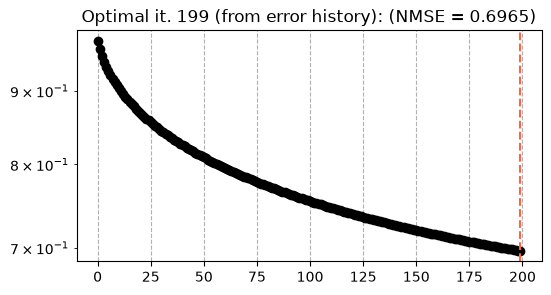

In [14]:
error_hist = nmse_fun(x_est_h, problem.b_true.ravel(order="C")[:, None], axis=0)
k_opt = np.argmin(error_hist)
plt.figure(figsize = (6,3))
plt.semilogy(np.arange(len(error_hist)), error_hist, '-ok')
plt.axvline(k_opt, linestyle = '--', color = 'tomato')
plt.title("Optimal it. {} (from error history): (NMSE = {:.4f})".format(k_opt, error_hist[k_opt]))
plt.grid(linestyle = '--')
#plt.ylim((0.003, 0.03))
plt.show()

In [15]:
x_est = np.reshape(x_est_h[:,k_opt], problem.shape, order="C")
nmse = nmse_fun(x_meas = x_est, x_ref = problem.b_true)

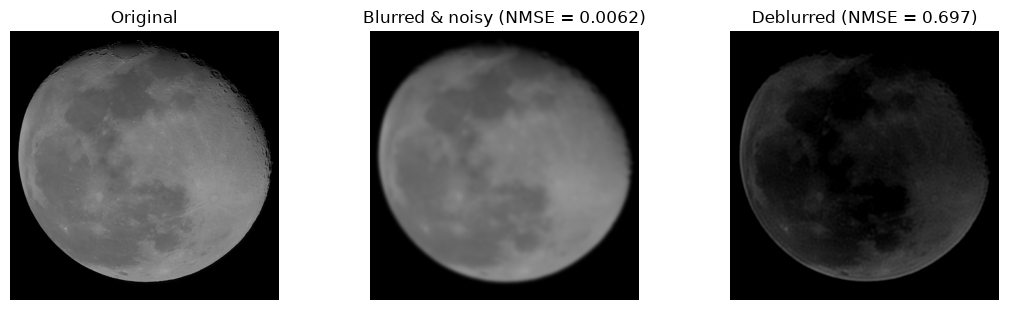

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
ax[0].imshow(problem.b_true, cmap="gray", vmin=0, vmax=1)
ax[0].set_title("Original")
ax[1].imshow(problem.b_noisy, cmap="gray", vmin=0, vmax=1)
ax[1].set_title("Blurred & noisy (NMSE = {:.4f})".format(nmse_b))
ax[2].imshow(x_est, cmap="gray", vmin=0, vmax=1)
ax[2].set_title("Deblurred (NMSE = {:.3f})".format(nmse))
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

### Question: What did you notice?

<details>
  <summary><b>▶ Click here to reveal the answer</b></summary>

  ### Answer

- Convergence (or semiconvergence) is slow, requiring a large number of iterations.
- In this particular example, the last iteration appears to yield the lowest NMSE (assuming that the true solution is known, which is generally not the case in practical applications).
- The reconstruction starts from a zero initial guess, $\mathbf{x}=[0,0,\ldots,0]^T$, and gradually approaches a regularized solution. As the number of iterations increases, the darker regions of the image tend to become brighter.
- The choice of $\omega$ plays an important role. Values that are too large can lead to divergence. When using `scipy.sparse.linalg.LinearOperator`, estimating a suitable value becomes more challenging because the matrix $\mathbf{A}$ is no longer explicitly available.

</details>


## 3.3. CGLS: Conjugate Gradient for Least Squares

The **CGLS** (Conjugate Gradient for Least Squares) method is an iterative algorithm for solving the least-squares problem in:

\begin{equation}
\min_{\mathbf{x}}
\|\mathbf{A}\mathbf{x}-\mathbf{b}\|_2^2.
\end{equation}

Like the Landweber method, CGLS uses the residual between the measured data and the data predicted by the current solution to improve the estimate. However, instead of following the gradient direction at every iteration, CGLS constructs **conjugate search directions** that make more efficient use of the information obtained in previous iterations.

As a result, CGLS generally converges much faster than Landweber, often producing useful reconstructions with relatively few iterations.

### CGLS and Iterative Regularization

Like Landweber, CGLS exhibits **semiconvergence** when applied to ill-posed problems. The first iterations recover the most relevant components of the solution, while later iterations may amplify the measurement noise.

Therefore, **the number of iterations acts as a regularization parameter**. Stopping the algorithm at an appropriate iteration can produce a better reconstruction than allowing it to converge fully.

An important practical advantage is that CGLS does not require a relaxation parameter, such as $\omega$, as in Landweber. The step sizes are computed automatically during the iterations.

We can now apply CGLS to the image deblurring problem using the same `scipy.sparse.linalg.LinearOperator` constructed previously, without explicitly forming either $\mathbf{A}$ or $\mathbf{A}^H\mathbf{A}$.

In [17]:
num_iterations = 100
x_est_h, sol_norms, res_norms = cgls(Aop, problem.b_noisy.ravel(order="C"), max_it=num_iterations)
print("Shape of Solution history: {}".format(x_est_h.shape))

Shape of Solution history: (160000, 100)


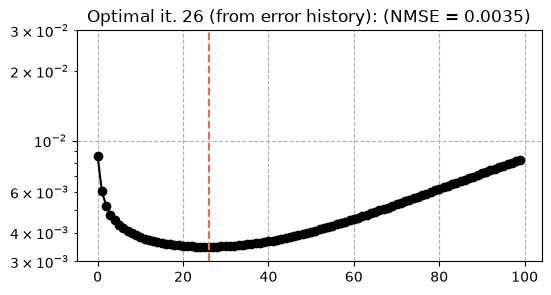

In [18]:
error_hist = nmse_fun(x_est_h, problem.b_true.ravel(order="C")[:, None], axis=0)
k_opt = np.argmin(error_hist)

plt.figure(figsize = (6,3))
plt.semilogy(np.arange(len(error_hist)), error_hist, '-ok')
plt.axvline(k_opt, linestyle = '--', color = 'tomato')
plt.title("Optimal it. {} (from error history): (NMSE = {:.4f})".format(k_opt, error_hist[k_opt]))
plt.grid(linestyle = '--')
plt.ylim((0.003, 0.03))
plt.show()

## 3.4. Choosing the Number of Iterations Using the L-Curve

In iterative regularization methods, the number of iterations $k$ acts as a regularization parameter. One way to select this parameter is through the **L-curve**, constructed from the residual and solution norms at each iteration:

\begin{equation}
\rho_k = \|\mathbf{A}\mathbf{x}^{[k]}-\mathbf{b}\|_2,
\qquad
\eta_k = \|\mathbf{x}^{[k]}\|_2.
\end{equation}

The curve is plotted on logarithmic axes, with $\rho_k$ on the horizontal axis and $\eta_k$ on the vertical axis. When the curve exhibits its characteristic L-shape, the corner represents a compromise between fitting the measured data and limiting the magnitude of the solution.

To identify this corner automatically, we use the `lcurve_discrete` function from `PyRegTools`, based on the **triangle method** proposed by Castellanos et al. (2002).

The algorithm consists of three main steps:

1. **Filtering:** removes points that do not follow the expected L-curve behavior, namely a decreasing residual norm accompanied by an increasing solution norm.
2. **Normalization:** transforms the norms into logarithmic coordinates and rescales each axis to the interval $[-10,10]$.
3. **Corner detection:** constructs triangles between points on the curve and uses their geometric properties, particularly orientation and internal angles, to identify the corner.

The function returns the index of the selected solution in the original iteration history, allowing us to retrieve the corresponding regularized solution directly.

Note that not all iterative methods produce a well-defined L-shaped curve. In such cases, automatic corner detection may not provide a reliable stopping criterion.

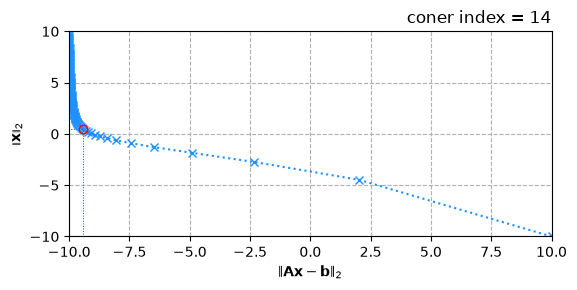

In [19]:
k_l = lcurve_discrete(res_norms, sol_norms, plotit=True)
x_est = np.reshape(x_est_h[:,k_l], problem.shape, order="C")
nmse = nmse_fun(x_meas = x_est, x_ref = problem.b_true)

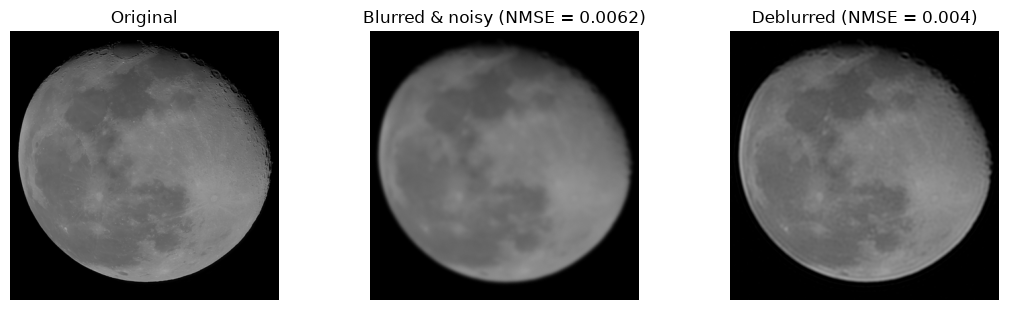

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
ax[0].imshow(problem.b_true, cmap="gray", vmin=0, vmax=1)
ax[0].set_title("Original")
ax[1].imshow(problem.b_noisy, cmap="gray", vmin=0, vmax=1)
ax[1].set_title("Blurred & noisy (NMSE = {:.4f})".format(nmse_b))
ax[2].imshow(x_est, cmap="gray", vmin=0, vmax=1)
ax[2].set_title("Deblurred (NMSE = {:.3f})".format(nmse))
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

# 4. Concluding Remarks

In this notebook, we explored image deblurring as an inverse problem and investigated how iterative regularization methods can be applied to large-scale problems.

The main takeaways are:

- **Matrix-free computation:** By implementing the forward and adjoint operators using the FFT, we can solve the inverse problem without explicitly constructing or storing the large matrix $\mathbf{A}$.
- **Iterative regularization:** Methods such as Landweber and CGLS progressively improve the reconstruction. However, because of **semiconvergence**, performing more iterations does not necessarily produce a better solution.
- **Computational efficiency:** CGLS generally reaches useful reconstructions in fewer iterations than Landweber and does not require selecting a relaxation parameter.
- **Stopping criteria:** The number of iterations acts as a regularization parameter. The L-curve provides a possible criterion for selecting a suitable stopping point without knowing the true image, although its reliability depends on the shape of the curve.

The central lesson is that **regularization is not always achieved by explicitly modifying the inverse problem**, as in Tikhonov regularization. It can also emerge from the iterative solution process itself, provided the iterations are appropriately stopped.

This makes iterative methods particularly attractive for large-scale inverse problems, where explicitly constructing or factorizing the system matrix would be computationally impractical.